### Problem 1

In [1]:
# Import and set up data an variables
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from IPython.display import display

data_path = Path('P6_lightcurve') if Path('P6_lightcurve').is_dir() else Path('pset6/P6_lightcurve')
photometry = pd.read_csv(data_path / 'lightcurve_2025-10-25.csv')
catalog = pd.read_csv(data_path / 'comparisons.csv').set_index('name')
star_names = ['T'] + [f'C{i}' for i in range(1, 9)]
comp_names = star_names[1:]
flux = photometry[[f'flux_{name}' for name in star_names]].to_numpy()
flux_err = photometry[[f'err_{name}' for name in star_names]].to_numpy()
comp_flux, comp_err = flux[:, 1:], flux_err[:, 1:]
time_bjd = photometry['bjd_tdb'].to_numpy()
time_hours = (time_bjd - time_bjd[0]) * 24
all_frames = np.ones(len(photometry), dtype=bool)
assert np.all(np.isfinite(flux)) and np.all(flux > 0)
assert np.all(np.isfinite(flux_err)) and np.all(flux_err > 0)

def constant_fit(y, error):
    weights = 1 / error**2
    mean = np.sum(weights * y, axis=0) / np.sum(weights, axis=0)
    chi2 = np.sum(((y - mean) / error)**2, axis=0)
    return mean, chi2 / (len(y) - 1)

def leave_one_out(indices, errors=comp_err):
    selected_flux = comp_flux[:, indices]
    selected_var = errors[:, indices]**2
    denominator = selected_flux.sum(axis=1, keepdims=True) - selected_flux
    denominator_var = selected_var.sum(axis=1, keepdims=True) - selected_var
    ratio = selected_flux / denominator
    error = np.sqrt(selected_var / denominator**2
                    + selected_flux**2 * denominator_var / denominator**4)
    return ratio, error

def target_curve(indices, errors=flux_err):
    # Sum the comparison fluxes and propagate the uncertainty from Eq. (2).
    comparison_sum = comp_flux[:, indices].sum(axis=1)
    comparison_variance = (errors[:, 1:][:, indices]**2).sum(axis=1)
    relative = flux[:, 0] / comparison_sum
    error = relative * np.sqrt((errors[:, 0] / flux[:, 0])**2
                               + comparison_variance / comparison_sum**2)
    return relative, error


def plot_comparisons(ratios, errors, indices, mask, title):
    fig, axes = plt.subplots(4, 2, figsize=(12, 10), sharex=True)
    for ax, column, index in zip(axes.flat, range(len(indices)), indices):
        mean, chi2 = constant_fit(ratios[mask, column], errors[mask, column])
        ax.errorbar(time_hours[mask], ratios[mask, column] / mean,
                    yerr=errors[mask, column] / mean, fmt='.', ms=2, alpha=0.65)
        ax.axhline(1, color='black', lw=0.7)
        ax.set_title(f'{comp_names[index]}: reduced chi-square = {chi2:.2f}')
        ax.set_ylabel('Relative flux')
    for ax in axes.flat[len(indices):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel('Hours from first exposure (BJD_TDB)')
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


#### Part 1.1

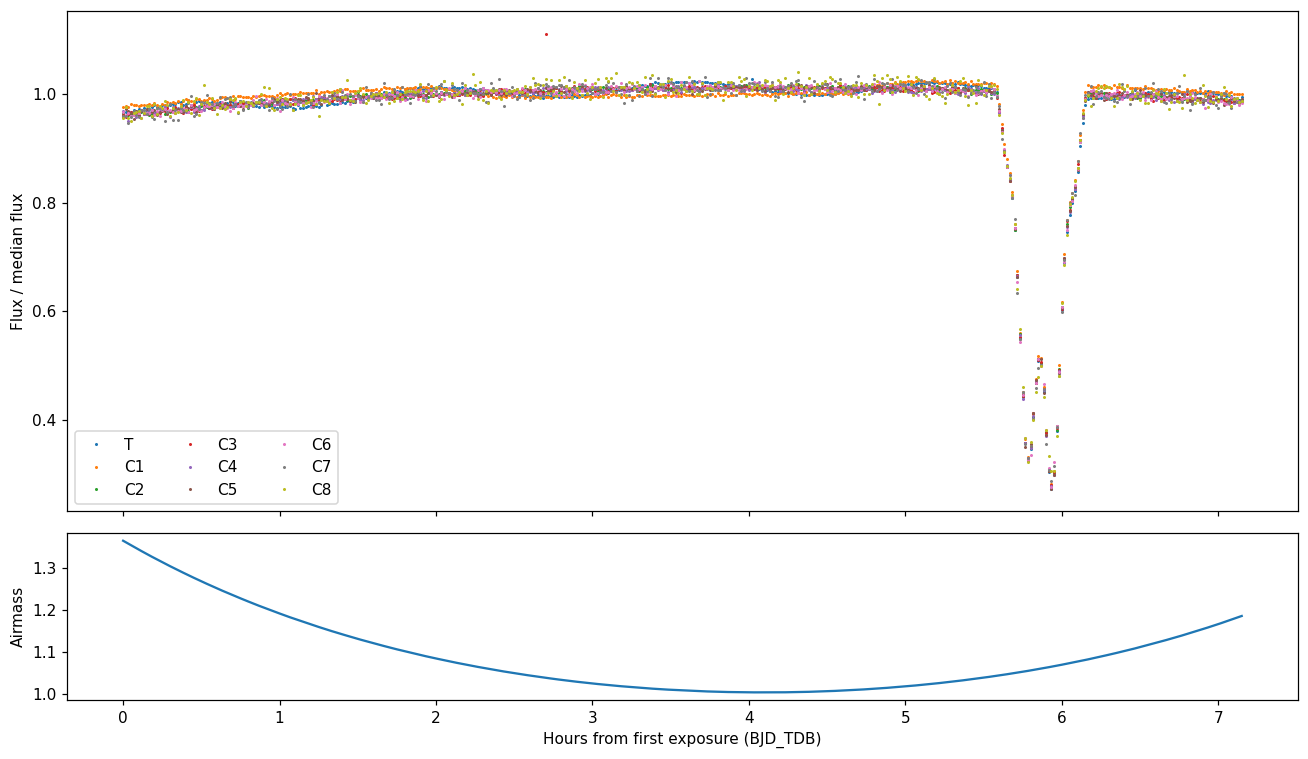

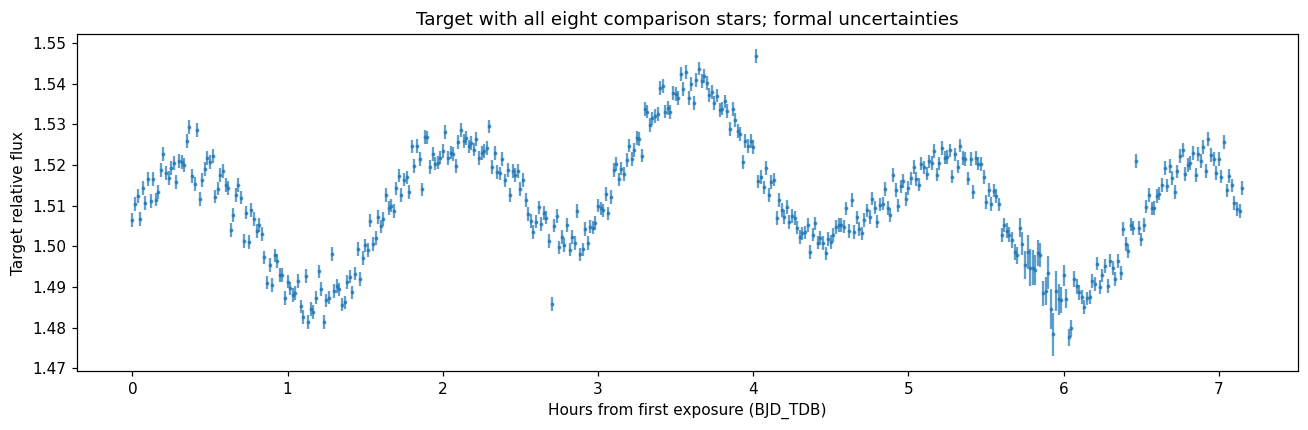

In [2]:
# Plot the flux of every star against time, each divided by its own median flux so that they share an axis, 
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1]})
for column, name in enumerate(star_names):
    axes[0].plot(time_hours, flux[:, column] / np.median(flux[:, column]),
                 '.', ms=2, label=name)
axes[0].set_ylabel('Flux / median flux')
axes[0].legend(ncol=3)

# Plot the airmass beneath on a separate panel.
axes[1].plot(time_hours, photometry['airmass'])
axes[1].set_ylabel('Airmass')
axes[1].set_xlabel('Hours from first exposure (BJD_TDB)')
fig.tight_layout()
plt.show()

# Calculate the target's relative flux using all eight comparison stars, with its uncertainty from Eq. (2), and plot it
initial_relative_flux, initial_relative_err = target_curve(np.arange(8))
plt.figure(figsize=(12, 4))
plt.errorbar(time_hours, initial_relative_flux, yerr=initial_relative_err,
             fmt='.', ms=3, alpha=0.7)
plt.xlabel('Hours from first exposure (BJD_TDB)')
plt.ylabel('Target relative flux')
plt.title('Target with all eight comparison stars; formal uncertainties')
plt.tight_layout()
plt.show()


##### Written

The stars share a slow flux trend as the airmass changes, and all show a sharp dip near 5.8–6.1 hours. The common dip is consistent with reduced transparency, such as passing cloud; the airmass varies smoothly and cannot explain it. Calibrating our photometry removes most of this common variation. The target still varies, but using all eight comparisons also introduces structure from the variable comparison star. I divided T's flux by the sum of all eight comparison fluxes, as in Eq. (2). The uncertainty of that sum comes from adding the comparison variances, and then I propagated both T's uncertainty and the comparison-sum uncertainty into the ratio. This ratio is plotted directly, without normalizing the comparison stars or the final ratio by their medians.

#### Part 1.2

,star,reduced_chi2
0,C1,42.067261
1,C2,7.379451
2,C3,8.671724
3,C4,4.390135
4,C5,3.000166
5,C6,2.442031
6,C7,1.439294
7,C8,1.179898


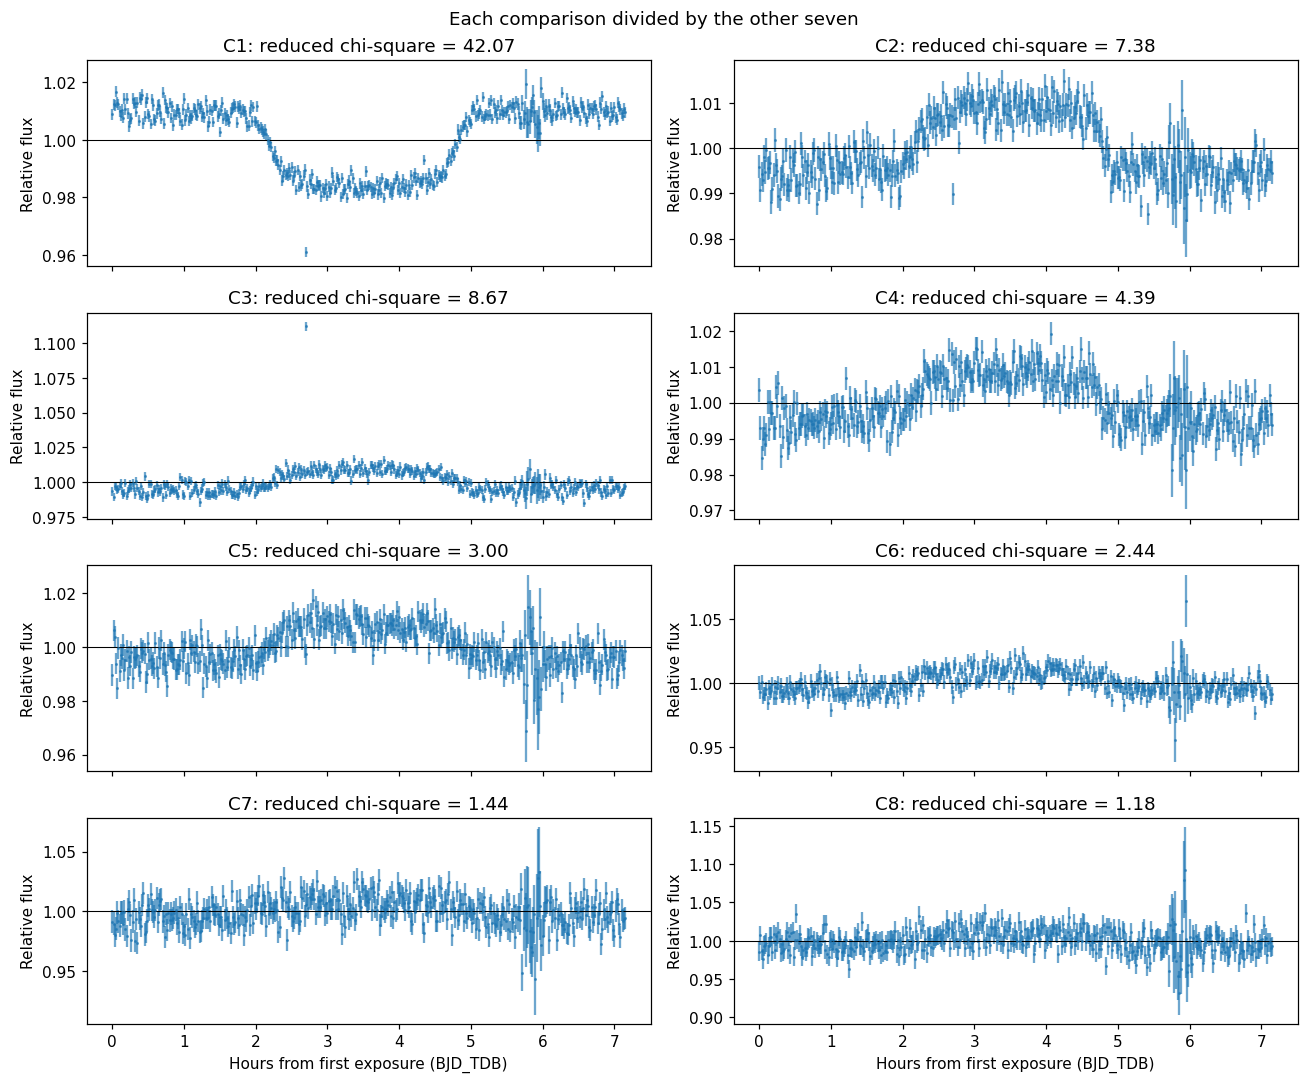

In [3]:
# For each comparison star:
comparison_ratios, comparison_errors = leave_one_out(np.arange(8))
comparison_chi2 = []
for j, name in enumerate(comp_names):
    # Compute its flux divided by sum of other seven stars
    y, error = comparison_ratios[:, j], comparison_errors[:, j]

    # compute \chi_\nu^2 statistic, 1/(N-1) sum [(y_i-y mean)/\sigma_i]^2
    mean, chi2 = constant_fit(y, error)
    comparison_chi2.append(chi2)

# Plot all eight curves from above for loop (curve over time)
display(pd.DataFrame({'star': comp_names, 'reduced_chi2': comparison_chi2}))
plot_comparisons(comparison_ratios, comparison_errors, np.arange(8),
                 all_frames, 'Each comparison divided by the other seven')


##### Written

C1 has the largest reduced chi-square, about 42.07, and a sustained dip with a flat bottom, making it unsuitable as a constant comparison. Its variation also appears with the opposite sign in the other stars' ratios because C1 is included in their denominators. C3, on the other hand, has an isolated positive outlier at row 162, at 2025-10-25 03:12:02 UTC, and naturally that frame also affects other ratios. These patterns distinguish sustained variability in C1 from the single bad measurement. The ratios use the sum of the other stars, with numerator and denominator uncertainties propagated, and each constant level is fitted with an inverse-variance weighted mean.

Variable comparison: C1
Bad frame: row 162 (zero-based), 2025-10-25T03:12:02 UTC


,star,r_magnitude,reduced_chi2
0,C2,12.244,1.261863
1,C3,12.500,1.218221
2,C4,12.672,1.337215
3,C5,12.953,1.054129
4,C6,13.403,1.195823
5,C7,14.108,1.159331
6,C8,14.443,0.977273


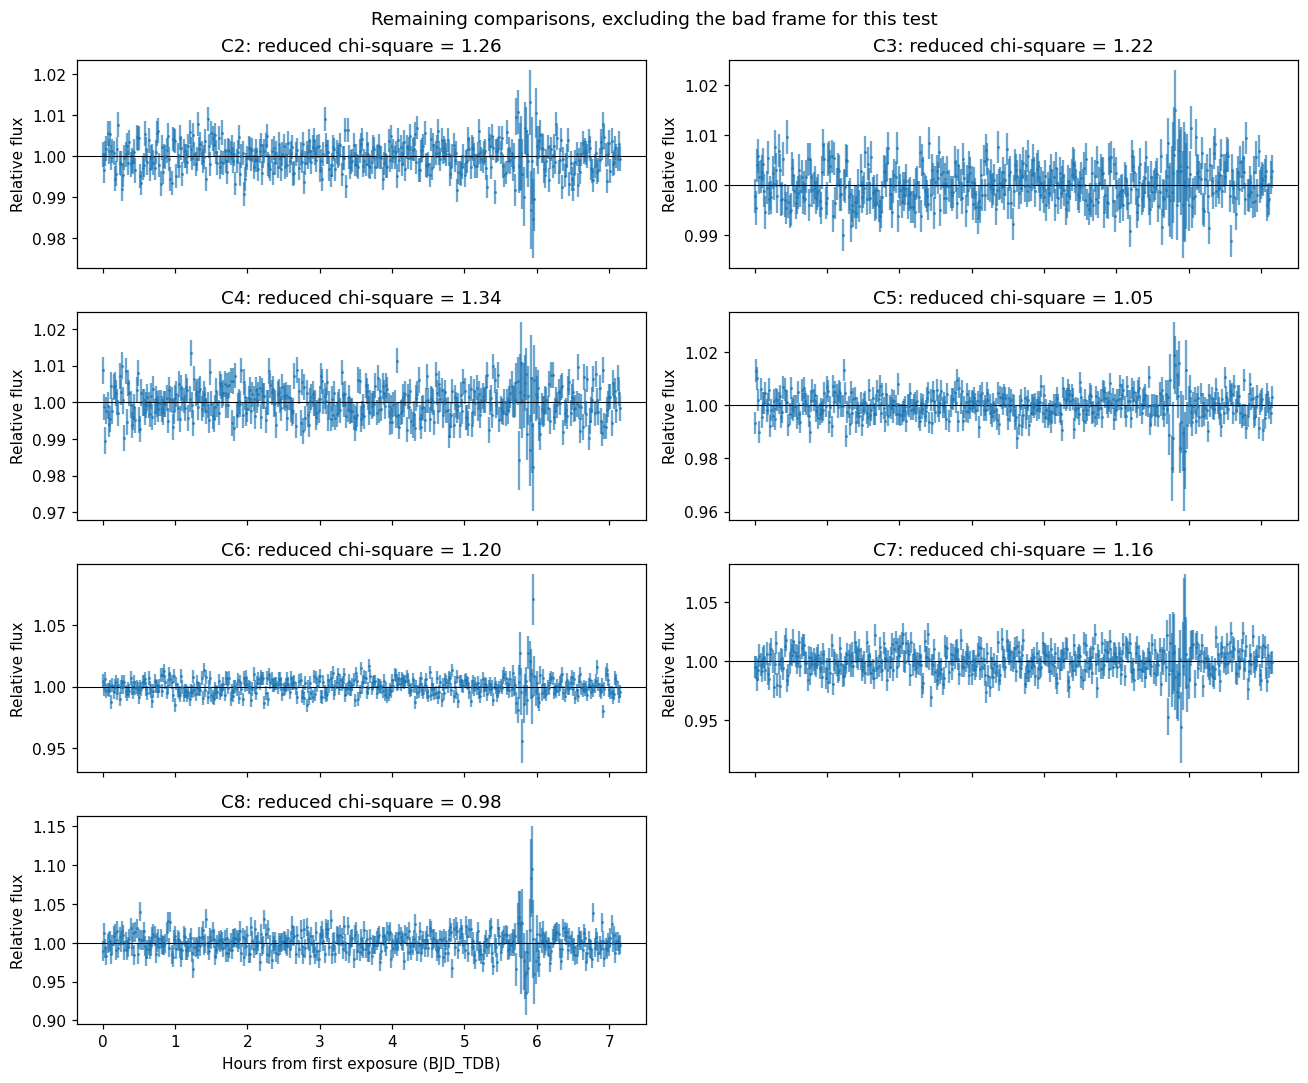

In [4]:
# Drop the star that is not constant from the ensemble, leave out the single frame
# that is bad (for this test only), and repeat.
# Remove each star's largest residual when ranking sustained variability.
trimmed_chi2 = []
for j in range(8):
    y, error = comparison_ratios[:, j], comparison_errors[:, j]
    mean, _ = constant_fit(y, error)
    keep = all_frames.copy()
    keep[np.argmax(np.abs((y - mean) / error))] = False
    trimmed_chi2.append(constant_fit(y[keep], error[keep])[1])
variable_index = int(np.argmax(trimmed_chi2))
trusted_indices = np.delete(np.arange(8), variable_index)
clean_ratios, clean_errors = leave_one_out(trusted_indices)
clean_mean, _ = constant_fit(clean_ratios, clean_errors)
frame_score = np.max(np.abs((clean_ratios - clean_mean) / clean_errors), axis=1)
bad_frame = int(np.argmax(frame_score))
test_frames = all_frames.copy()
test_frames[bad_frame] = False
_, clean_chi2 = constant_fit(clean_ratios[test_frames], clean_errors[test_frames])
print(f'Variable comparison: {comp_names[variable_index]}')
print(f'Bad frame: row {bad_frame} (zero-based), {photometry.loc[bad_frame, "date_obs"]} UTC')
display(pd.DataFrame({'star': np.array(comp_names)[trusted_indices],
                      'r_magnitude': catalog.loc[np.array(comp_names)[trusted_indices], 'r'].to_numpy(),
                      'reduced_chi2': clean_chi2}))
plot_comparisons(clean_ratios, clean_errors, trusted_indices, test_frames,
                 'Remaining comparisons, excluding the bad frame for this test')


##### Written again

After dropping C1 and excluding row 162 for this test, the remaining reduced chi-squares are 1.262, 1.218, 1.337, 1.054, 1.196, 1.159, and 0.977 for C2–C8. The sustained structure disappears, supporting use of these seven comparisons. The scatter is still somewhat larger than the formal errors predict, especially for the brighter stars. The transparency dip remains in the raw fluxes but largely cancels in the ratios; its lower photon counts increase the relative uncertainties.

#### Part 1.3

Fractional scintillation s = 0.001612 (0.161%)
Pooled reduced chi-square = 1.000000
The leave-one-out curves share comparison stars, so their chi-squares are correlated.


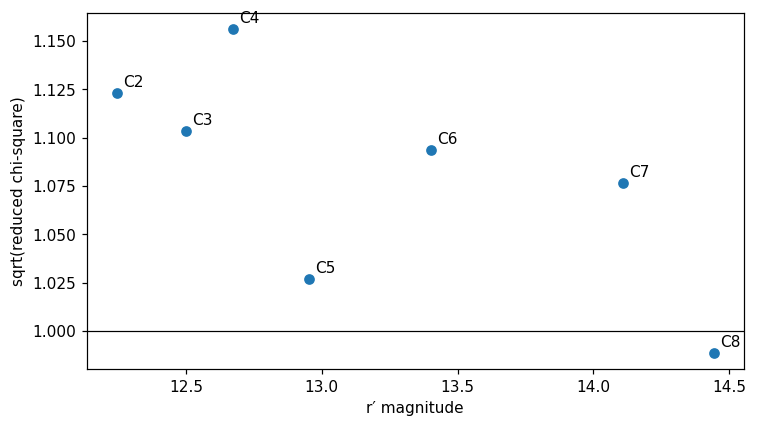

,star,formal_reduced_chi2,adjusted_reduced_chi2
0,C2,1.261863,0.935644
1,C3,1.218221,0.938543
2,C4,1.337215,1.066191
3,C5,1.054129,0.893676
4,C6,1.195823,1.087923
5,C7,1.159331,1.120114
6,C8,0.977273,0.957909


In [5]:
# Plot sqrt(\chi_\nu^2) against r′ magnitude for each remaining comp. star
magnitudes = catalog.loc[np.array(comp_names)[trusted_indices], 'r'].to_numpy()
plt.figure(figsize=(7, 4))
plt.scatter(magnitudes, np.sqrt(clean_chi2), label='Formal uncertainties')
for magnitude, chi2, index in zip(magnitudes, clean_chi2, trusted_indices):
    plt.annotate(comp_names[index], (magnitude, np.sqrt(chi2)), xytext=(4, 4),
                 textcoords='offset points')
plt.axhline(1, color='black', lw=0.8)
plt.xlabel("r′ magnitude")
plt.ylabel('sqrt(reduced chi-square)')
plt.tight_layout()
plt.show()

# Add scintillation s F_j in quadrature to uncertainty of every star
def errors_with_scintillation(s):
    return np.hypot(flux_err, s * flux)

def ensemble_chi2(s):
    errors = errors_with_scintillation(s)[:, 1:]
    ratios, ratio_errors = leave_one_out(trusted_indices, errors)
    _, chi2 = constant_fit(ratios[test_frames], ratio_errors[test_frames])
    # Equal frame counts and one fitted mean per star give equal degrees of freedom.
    return np.mean(chi2)

# Find value of s such that comparison stars together give \chi_\nu^2 = 1
if ensemble_chi2(0) <= 1:
    scintillation = 0.0
else:
    upper = 0.001
    while ensemble_chi2(upper) > 1:
        upper *= 2
    scintillation = brentq(lambda s: ensemble_chi2(s) - 1, 0, upper)
updated_errors = errors_with_scintillation(scintillation)
adjusted_ratios, adjusted_ratio_errors = leave_one_out(trusted_indices, updated_errors[:, 1:])
_, adjusted_chi2 = constant_fit(adjusted_ratios[test_frames], adjusted_ratio_errors[test_frames])
print(f'Fractional scintillation s = {scintillation:.6f} ({100 * scintillation:.3f}%)')
print(f'Pooled reduced chi-square = {ensemble_chi2(scintillation):.6f}')
print('The leave-one-out curves share comparison stars, so their chi-squares are correlated.')
display(pd.DataFrame({'star': np.array(comp_names)[trusted_indices],
                      'formal_reduced_chi2': clean_chi2,
                      'adjusted_reduced_chi2': adjusted_chi2}))


##### Written

The brighter comparison stars generally have larger $\sqrt{\chi_\nu^2}$, consistent with an additional fractional noise term becoming more visible as photon noise decreases. Adding $sF_j$ in quadrature to every star's flux uncertainty gives $s=0.001612$, or 0.161%, when the pooled comparison-star reduced chi-square is one. I fitted this term using C2–C8 with the single bad frame excluded. The individual adjusted reduced chi-squares range from about 0.894 to 1.120; the leave-one-out curves share stars, so their statistics are correlated. This is an effective fractional noise floor, consistent with scintillation, rather than proof that it is definitively scintillation. The final target curve uses C2–C8 and the updated uncertainties, restores all 430 frames, and flags the suspect frame. It shows roughly 3% peak-to-peak, repeating variability with a period of about 1.6–1.7 hours by visual inspection.

Using a typical airmass of about 1.06, Young's formula gives $s\approx0.00096$, or 0.096%, for this telescope and exposure time. Our fitted 0.161% is about 1.7 times larger, so they are in the same general range but don't agree exactly; the fitted extra scatter could include things besides scintillation. The target's error bars change the most: its raw-flux uncertainty grows by about a factor of 2.9 at typical frames, versus about 1.7 for C1 and much smaller changes for the faint comparisons. The target has so many photons that its original fractional error was especially small, so adding the same fractional noise to everyone affects it most.

430 frames retained; comparisons: C2, C3, C4, C5, C6, C7, C8


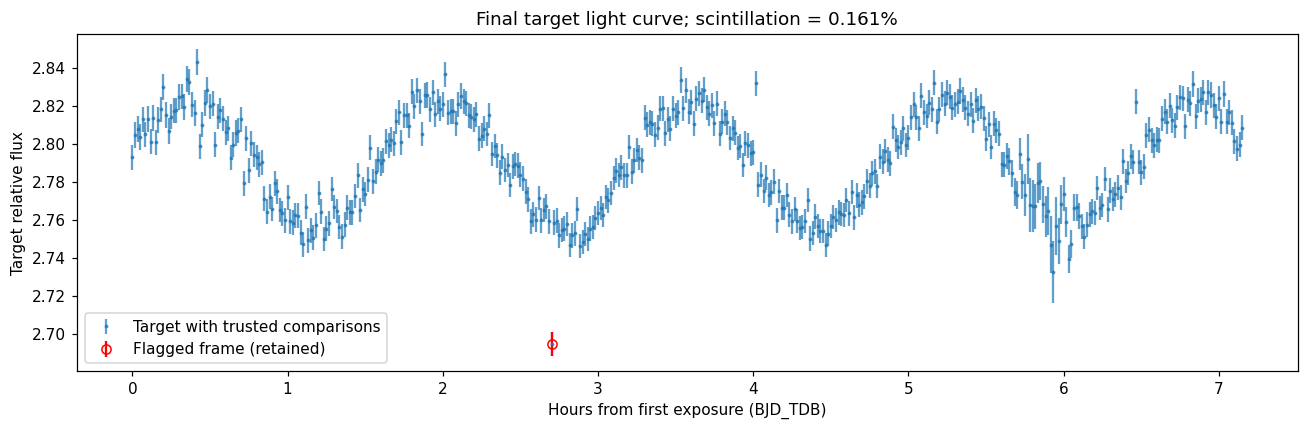

,bjd_tdb,time_hours,relative_flux,relative_flux_err,flagged_frame
0,2.460974e+06,0.000000,2.793003,0.006641,False
1,2.460974e+06,0.016464,2.804760,0.006670,False
2,2.460974e+06,0.032976,2.807980,0.006683,False
3,2.460974e+06,0.050160,2.803628,0.006667,False
4,2.460974e+06,0.067032,2.812988,0.006687,False


In [6]:
# Rebuild the target's relative light curve with the new uncertainties and the
# comparison stars you trust; this is the light curve you will use from now on
relative_flux, relative_flux_err = target_curve(trusted_indices, updated_errors)
light_curve = pd.DataFrame({'bjd_tdb': time_bjd, 'time_hours': time_hours,
                            'relative_flux': relative_flux,
                            'relative_flux_err': relative_flux_err,
                            'flagged_frame': ~test_frames})
fig, ax = plt.subplots(figsize=(12, 4))
ax.errorbar(time_hours, relative_flux, yerr=relative_flux_err,
            fmt='.', ms=3, alpha=0.7, label='Target with trusted comparisons')
ax.errorbar(time_hours[bad_frame], relative_flux[bad_frame],
            yerr=relative_flux_err[bad_frame], fmt='o', mfc='none', color='red',
            label='Flagged frame (retained)')
ax.set_xlabel('Hours from first exposure (BJD_TDB)')
ax.set_ylabel('Target relative flux')
ax.set_title(f'Final target light curve; scintillation = {100 * scintillation:.3f}%')
ax.legend()
fig.tight_layout()
plt.show()
print(f'{len(light_curve)} frames retained; comparisons: {", ".join(np.array(comp_names)[trusted_indices])}')
display(light_curve.head())


### Problem 2

#### Part 2.1

Rows rejected by whole-curve clipping: [162]


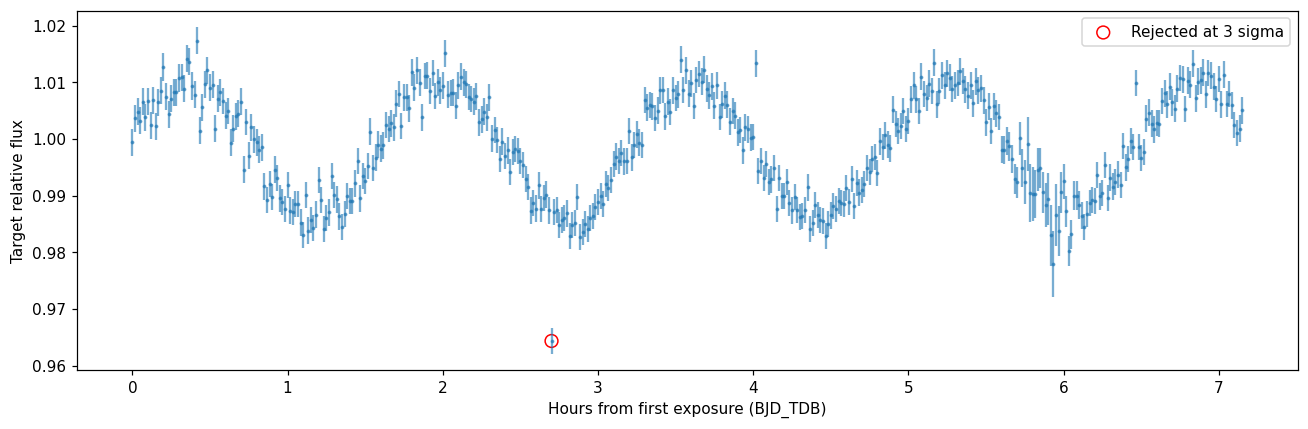

In [7]:
# This is wrong, but for now we test applying astropy.stats.sigma_clip at to the whole light curve, as though it were constant
from astropy.stats import sigma_clip
from scipy.ndimage import median_filter
from scipy.special import erfc, erfcinv
from scipy.stats import norm
from scipy.optimize import curve_fit, OptimizeWarning
import warnings

# Use the sum of comparison fluxes and propagate the uncertainty as in Eq. (2).
def summed_relative_flux(indices, errors):
    comparison_sum = comp_flux[:, indices].sum(axis=1)
    comparison_error = np.sqrt((errors[:, 1:][:, indices]**2).sum(axis=1))
    ratio = flux[:, 0] / comparison_sum
    ratio_error = np.hypot(errors[:, 0] / comparison_sum,
                           flux[:, 0] * comparison_error / comparison_sum**2)
    scale = np.median(ratio)
    return ratio / scale, ratio_error / scale

relative_flux, relative_flux_err = summed_relative_flux(trusted_indices, updated_errors)
clipped_flux = sigma_clip(relative_flux, sigma=3)
sigma_rejected = np.ma.getmaskarray(clipped_flux)
print('Rows rejected by whole-curve clipping:', np.flatnonzero(sigma_rejected))
plt.figure(figsize=(12, 4))
plt.errorbar(time_hours, relative_flux, yerr=relative_flux_err, fmt='.', ms=3, alpha=0.6)
plt.scatter(time_hours[sigma_rejected], relative_flux[sigma_rejected],
            facecolors='none', edgecolors='red', s=70, label='Rejected at 3 sigma')
plt.xlabel('Hours from first exposure (BJD_TDB)')
plt.ylabel('Target relative flux')
plt.legend()
plt.tight_layout()
plt.show()


##### Written

It only rejects a single exposure around 2.7 hours past first exposure, which is far lower than every other measurement during the night. However, we can visually identify several outliers that seem pretty far off (e.g. measurements around 0.43, 4, and 6.5 hours) which have not been removed because the 3 sigma clipping gives an unrealistically large variance because such clipping treats the source as a constant source rather than the variable source it is (and thus overestimating its variance).

#### Part 2.2

Chauvenet threshold: 3.248 sigma
Expected rejections from Gaussian noise: 0.50


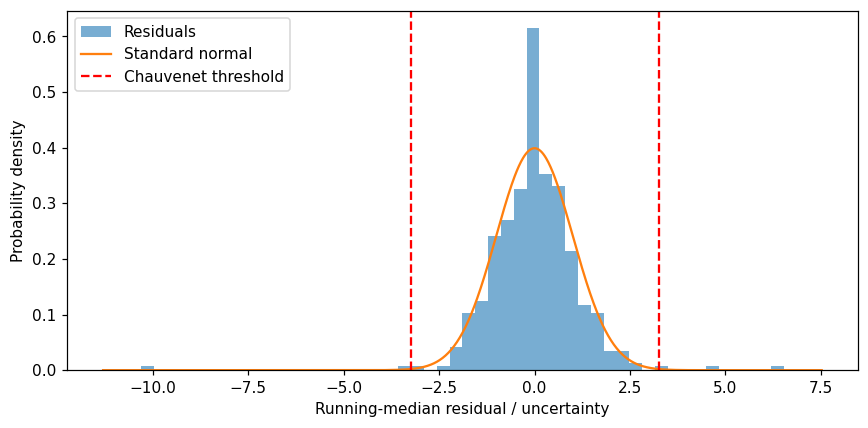

,row,date_obs,normalized_residual,whole_curve_rejected
0,26,2025-10-25T00:56:02,-3.321226,False
1,162,2025-10-25T03:12:02,-10.299753,True
2,241,2025-10-25T04:31:01,6.522309,False
3,388,2025-10-25T06:58:00,4.776663,False


,row,date_obs,bjd_tdb,exptime,airmass,fwhm,sky,flux_T,err_T,flux_C1,err_C1,flux_C2,err_C2,flux_C3,err_C3,flux_C4,err_C4,flux_C5,err_C5,flux_C6,err_C6,flux_C7,err_C7,flux_C8,err_C8
26,26,2025-10-25T00:56:02,2.460974e+06,45.0,1.2790,5.97,128.2,2941933.7,1768.8,895038.0,1040.0,289095.9,689.7,227171.2,643.2,194485.9,617.3,150428.7,580.5,99622.0,535.0,52808.5,489.3,37557.6,473.4
162,162,2025-10-25T03:12:02,2.460974e+06,45.0,1.0375,5.78,123.8,2989323.2,1780.5,902645.2,1041.0,296754.2,691.2,259390.0,663.6,201895.0,618.8,155308.2,579.9,101849.8,531.8,54066.3,484.8,39989.2,470.1
241,241,2025-10-25T04:31:01,2.460974e+06,45.0,1.0028,5.81,123.1,3083626.1,1806.6,904759.0,1041.6,299483.6,692.6,236518.8,645.5,201579.1,617.8,155051.4,579.0,102944.5,532.1,54075.3,484.0,39231.7,468.4
388,388,2025-10-25T06:58:00,2.460974e+06,45.0,1.1074,5.77,125.0,3025070.3,1791.0,917070.5,1048.6,294181.5,690.5,232256.2,644.1,198065.9,617.0,153507.8,579.7,101549.3,533.0,53528.3,485.9,38814.0,470.5


,C1,C2,C3,C4,C5,C6,C7,C8
row,,,,,,,,
26,-0.642779,1.766628,0.340343,0.849720,1.168795,1.602990,2.399278,-1.334715
162,-0.190658,-0.482046,31.174133,1.996246,0.737296,-0.410014,0.717865,0.925608
241,-1.102728,0.183123,0.378826,0.242250,-0.637287,-0.193765,0.379230,-0.629853
388,-0.122268,-0.114964,-1.049123,-0.673805,0.000000,0.543429,0.690778,0.000000


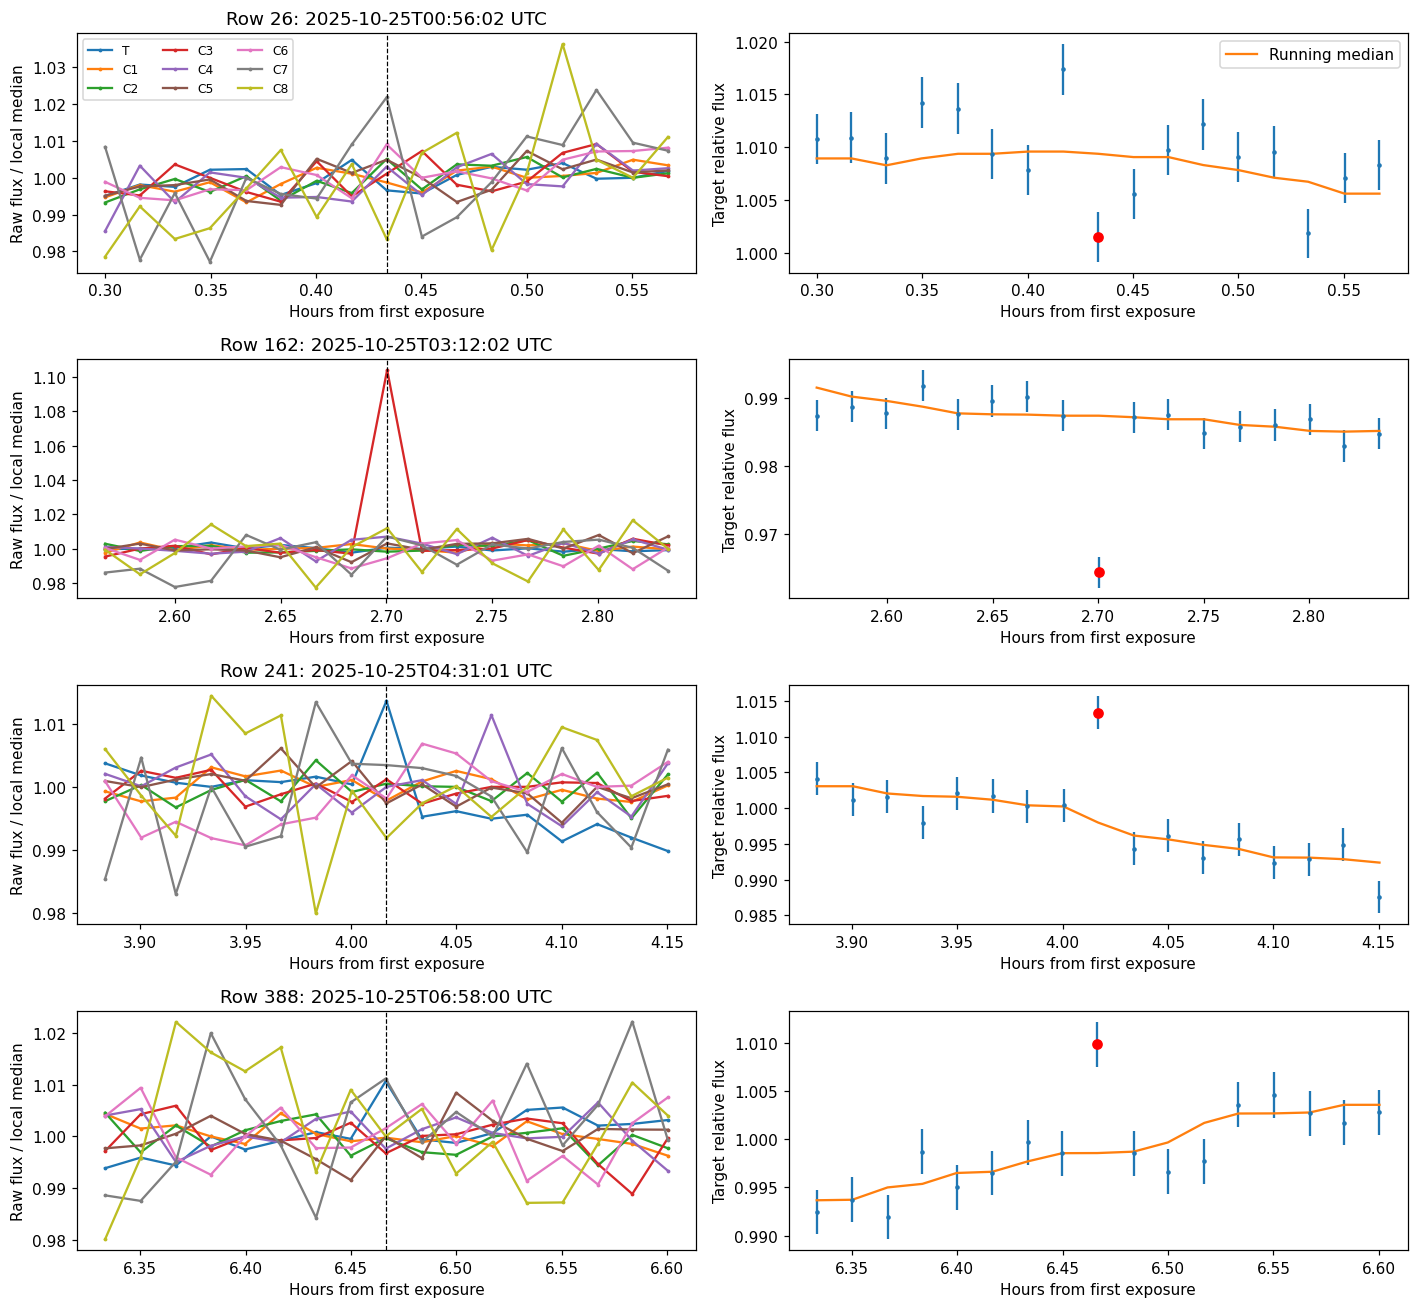

In [8]:
# Subtract a running median, scipy.ndimage.median_filter over 15
# frames, and normalize the residuals by their error bars.
running_median = median_filter(relative_flux, size=15, mode='reflect')
median_residuals = relative_flux - running_median
normalized_residuals = median_residuals / relative_flux_err

# Plot a histogram of them over a standard normal distribution.
plt.figure(figsize=(8, 4))
plt.hist(normalized_residuals, bins=50, density=True, alpha=0.6, label='Residuals')
z_grid = np.linspace(normalized_residuals.min() - 1, normalized_residuals.max() + 1, 1000)
plt.plot(z_grid, norm.pdf(z_grid), label='Standard normal')

# Apply Chauvenet's criterion and show the rejected points.
n_frames = len(relative_flux)
chauvenet_limit = np.sqrt(2) * erfcinv(0.5 / n_frames)
expected_tail_count = n_frames * erfc(np.abs(normalized_residuals) / np.sqrt(2))
rejected = expected_tail_count < 0.5
keep_frames = ~rejected
rejected_rows = np.flatnonzero(rejected)
plt.axvline(-chauvenet_limit, color='red', ls='--')
plt.axvline(chauvenet_limit, color='red', ls='--', label='Chauvenet threshold')
plt.xlabel('Running-median residual / uncertainty')
plt.ylabel('Probability density')
plt.legend()
plt.tight_layout()
plt.show()
print(f'Chauvenet threshold: {chauvenet_limit:.3f} sigma')
print(f'Expected rejections from Gaussian noise: {n_frames * erfc(chauvenet_limit / np.sqrt(2)):.2f}')
display(pd.DataFrame({'row': rejected_rows,
                      'date_obs': photometry.loc[rejected, 'date_obs'].to_numpy(),
                      'normalized_residual': normalized_residuals[rejected],
                      'whole_curve_rejected': sigma_rejected[rejected]}))

# Check the comparison stars and the other columns in every rejected frame.
comparison_medians = median_filter(comp_flux, size=(15, 1), mode='reflect')
comparison_residuals = (comp_flux - comparison_medians) / updated_errors[:, 1:]
frame_details = photometry.loc[rejected].copy()
frame_details.insert(0, 'row', rejected_rows)
with pd.option_context('display.max_columns', None):
    display(frame_details)
display(pd.DataFrame(comparison_residuals[rejected], index=rejected_rows,
                     columns=comp_names).rename_axis('row'))

fig, axes = plt.subplots(len(rejected_rows), 2, figsize=(13, 3 * len(rejected_rows)),
                         squeeze=False)
for row, ax_pair in zip(rejected_rows, axes):
    nearby = np.arange(max(0, row - 8), min(n_frames, row + 9))
    for column, name in enumerate(star_names):
        local_flux = flux[nearby, column] / np.median(flux[nearby, column])
        ax_pair[0].plot(time_hours[nearby], local_flux, '.-', ms=3, label=name)
    ax_pair[0].axvline(time_hours[row], color='black', ls='--', lw=0.8)
    ax_pair[0].set_ylabel('Raw flux / local median')
    ax_pair[0].set_title(f'Row {row}: {photometry.loc[row, "date_obs"]} UTC')
    ax_pair[1].errorbar(time_hours[nearby], relative_flux[nearby],
                        yerr=relative_flux_err[nearby], fmt='.', ms=4)
    ax_pair[1].plot(time_hours[nearby], running_median[nearby], label='Running median')
    ax_pair[1].scatter(time_hours[row], relative_flux[row], color='red', zorder=3)
    ax_pair[1].set_ylabel('Target relative flux')
    for ax in ax_pair:
        ax.set_xlabel('Hours from first exposure')
axes[0, 0].legend(ncol=3, fontsize=8)
axes[0, 1].legend()
fig.tight_layout()
plt.show()


##### Written

It rejects the four points shown in the plots above (right column), at rows 26, 162, 241, and 388. We can look at what happened in each frame:

1. Around 0.43 hours after first exposure, the relative flux is about $3.32\sigma$ below the running median. C7 is noticeably high, and several other comparison stars are also on the high side, which pushes up the comparison sum and pulls down T's relative flux. However, C7 is only about $2.4\sigma$ high and is relatively faint, so I wouldn't blame the whole dip on C7 alone. There's no obvious jump in the sky, airmass, or image size. This one could just be an unlucky noise fluctuation, with some contribution from how the running median estimates the local curve.

2. Around 2.7 hours, C3 has a very large upward spike, about $31\sigma$ relative to its running median. Since C3 goes into the denominator, this makes T's relative flux look much lower even though T itself does not have a corresponding dip. This is the same bad frame found in 1.2. Extra counts from something like a cosmic ray in C3's aperture could do this, though we would need the image to check that. The large below-the-curve point thus comes from the comparison measurement.

3. Around 4.02 hours, T itself has a sharp upward spike, while the comparison stars look fairly normal. The relative-flux residual is about $6.52\sigma$. Some extra counts in T's aperture, e.g. from a cosmic ray, would explain the direction of the jump, but the table alone doesn't tell us exactly what happened. The sky, airmass, and image size don't show an obvious problem either.

4. Around 6.47 hours, T again records a higher flux than the nearby light curve would suggest, giving a relative-flux residual of about $4.78\sigma$. A few comparison stars are a little low too. There isn't an obvious field-wide jump or anything strange in the other columns, so again we can identify the bad-looking measurement without knowing its exact cause.

For 430 points, Chauvenet's cutoff is about $3.25\sigma$, rather than exactly $3\sigma$. A standard normal has about 0.116% of its points outside this cutoff on either side combined, so we would expect about 0.5 rejected points from Gaussian noise alone. We actually get four. The running median is only an estimate of the underlying curve, so the residuals are not perfectly independent standard-normal draws, but four is still more than the simple noise expectation.

#### Part 2.3

,selection,region,N,flux_residual_std,normalized_residual_std,Chauvenet_rejections
0,All frames,Cloud,36,0.003614,1.058919,0
1,All frames,Rest of night,394,0.002676,1.149564,4
2,Without outliers,Cloud,36,0.003614,1.058919,0
3,Without outliers,Rest of night,390,0.002184,0.930435,0


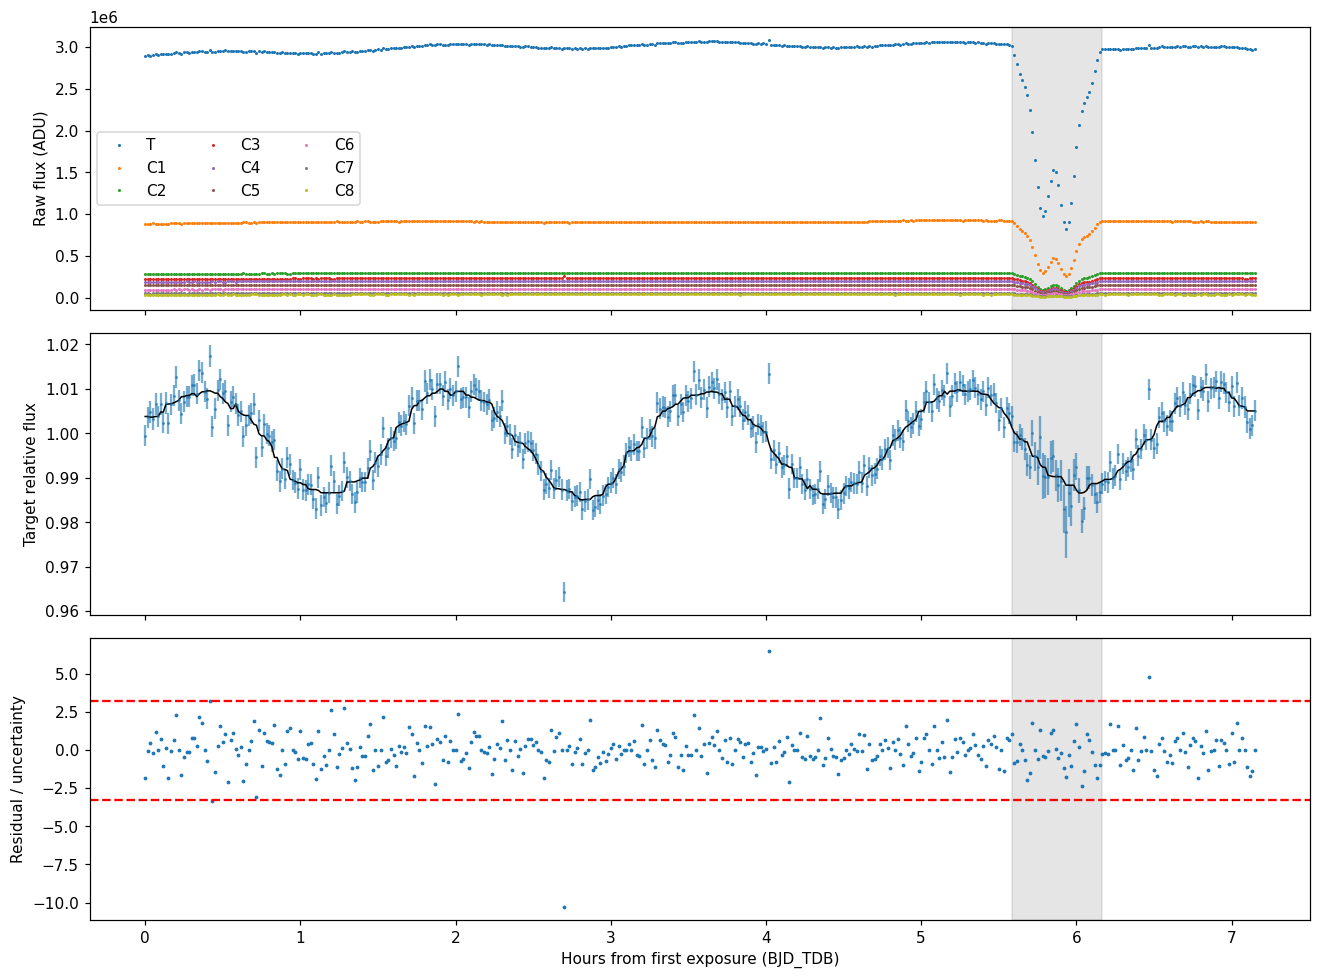

In [9]:
# Between 6:05 and 6:40 UTC, compare the scatter of their residuals about the
# running median with that of the rest of the night, first in units of relative flux and then normalized by
# their error bars.
utc = pd.to_datetime(photometry['date_obs'], utc=True)
cloud_frames = ((utc >= pd.Timestamp('2025-10-25 06:05:00', tz='UTC'))
                & (utc <= pd.Timestamp('2025-10-25 06:40:00', tz='UTC'))).to_numpy()
scatter_rows = []
for selection, mask in [('All frames', all_frames), ('Without outliers', keep_frames)]:
    for name, region in [('Cloud', cloud_frames), ('Rest of night', ~cloud_frames)]:
        use = mask & region
        scatter_rows.append({'selection': selection, 'region': name, 'N': use.sum(),
                             'flux_residual_std': np.std(median_residuals[use], ddof=1),
                             'normalized_residual_std': np.std(normalized_residuals[use], ddof=1),
                             'Chauvenet_rejections': np.sum(rejected & use)})
display(pd.DataFrame(scatter_rows))

# Plot the calibration stars and frames from 6:05 to 6:40 in absolute and relative flux
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for column, name in enumerate(star_names):
    axes[0].plot(time_hours, flux[:, column], '.', ms=2, label=name)
axes[0].set_ylabel('Raw flux (ADU)')
axes[0].legend(ncol=3)
axes[1].errorbar(time_hours, relative_flux, yerr=relative_flux_err, fmt='.', ms=2, alpha=0.6)
axes[1].plot(time_hours, running_median, color='black', lw=1)
axes[1].set_ylabel('Target relative flux')
axes[2].plot(time_hours, normalized_residuals, '.', ms=3)
axes[2].axhline(chauvenet_limit, color='red', ls='--')
axes[2].axhline(-chauvenet_limit, color='red', ls='--')
axes[2].set_ylabel('Residual / uncertainty')
axes[2].set_xlabel('Hours from first exposure (BJD_TDB)')
for ax in axes:
    ax.axvspan(time_hours[cloud_frames].min(), time_hours[cloud_frames].max(),
               color='gray', alpha=0.2)
fig.tight_layout()
plt.show()


##### Written

The cloudy frames look very dramatic in the raw fluxes: every star loses a large fraction of its measured light. However, most of this cancels when we divide T by the comparison sum, and the relative flux continues to follow the same general wiggle. None of the cloudy frames passes the Chauvenet rejection cutoff.

After leaving out the isolated outliers, the scatter about the running median is about 0.00361 during the cloud and 0.00218 during the rest of the night. So in relative-flux units the cloud is definitely noisier, by a factor of about 1.65. But in error-bar units the scatter is about 1.06 during the cloud versus 0.93 outside it, which is much more similar. Losing photons also increases the relative uncertainty, and the error bars mostly account for the extra scatter. I would keep these frames: they are less precise measurements, but they don't look like measurements of a different curve. Their larger uncertainties also give them less weight in the fit.

### Problem 3

#### Part 3.1

Approximate maximum times (hours): [0.35 2.   3.6  5.25 6.85]
Initial period: 1.625 hours; fractional semi-amplitude: 0.0120


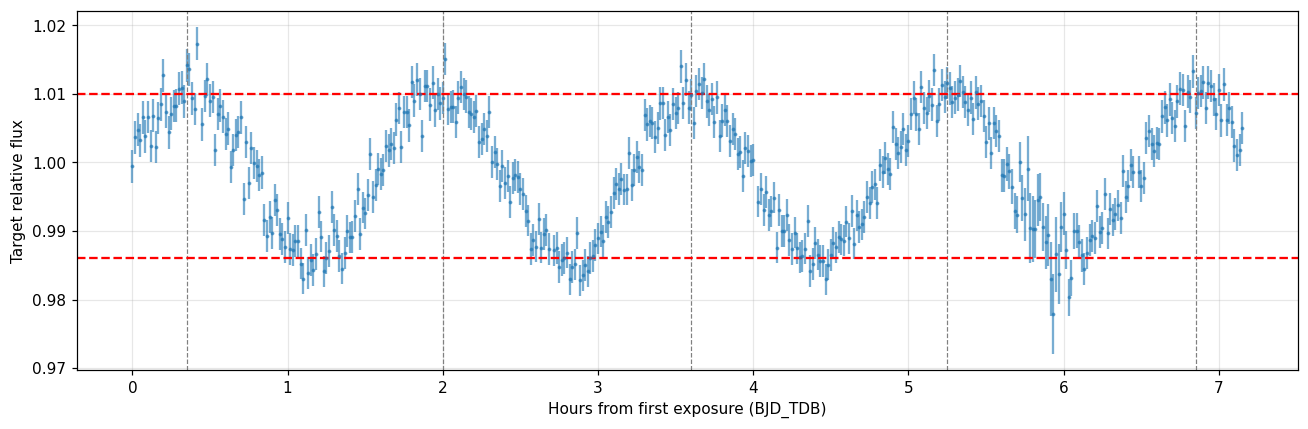

In [10]:
# From your light curve, without the points you rejected in section 2, read
# off the times of the maxima and the levels of the maxima and minima
plt.figure(figsize=(12, 4))
plt.errorbar(time_hours[keep_frames], relative_flux[keep_frames],
             yerr=relative_flux_err[keep_frames], fmt='.', ms=3, alpha=0.6)
plt.xlabel('Hours from first exposure (BJD_TDB)')
plt.ylabel('Target relative flux')
plt.grid(alpha=0.3)

# Estimate amplitude and period (using definition from problems, standard simple definition)
# Approximate readings from the plot, before fitting anything.
maximum_times = np.array([0.35, 2.00, 3.60, 5.25, 6.85])
maximum_level, minimum_level = 1.010, 0.986
period_guess = np.median(np.diff(maximum_times))
mean_guess = (maximum_level + minimum_level) / 2
amplitude_guess = (maximum_level - minimum_level) / (2 * mean_guess)
for maximum in maximum_times:
    plt.axvline(maximum, color='gray', ls='--', lw=0.8)
plt.axhline(maximum_level, color='red', ls='--')
plt.axhline(minimum_level, color='red', ls='--')
plt.tight_layout()
plt.show()
print(f'Approximate maximum times (hours): {maximum_times}')
print(f'Initial period: {period_guess:.3f} hours; fractional semi-amplitude: {amplitude_guess:.4f}')


##### Written

The maxima are roughly at 0.35, 2.0, 3.6, 5.25, and 6.85 hours after the first exposure, so the peak-to-peak spacing gives a period of about 1.6–1.65 hours; I used 1.625 hours as the starting estimate. The maximum and minimum relative fluxes are around 1.010 and 0.986, so the middle level is about 0.998. The fractional semi-amplitude is then approximately $(1.010-0.986)/(2\times0.998)\approx0.012$, or 1.2%. The full up-and-down change is about 2.4%; the amplitude in the model is half of that.

#### Part 3.2

Reduced chi-square: 0.9449
Full-BJD reduced chi-square: 10.1187
Covariance of the parameters could not be estimated


,parameter,value,uncertainty
0,f0,0.998256,0.000117
1,A (fraction),0.012013,0.000164
2,P (hours),1.625288,0.002878
3,phi (radians),1.428662,0.013749


,start,P_hours,P_error,A,reduced_chi2
0,Estimate,1.625288,0.002878,0.012013,0.944899
1,25% shorter,1.237919,0.010028,0.001915,13.458068


,parameter,full_BJD_value,uncertainty
0,f0,0.998000,inf
1,A (fraction),0.012024,inf
2,P (hours),1.625000,inf
3,phi (radians),1.473915,inf


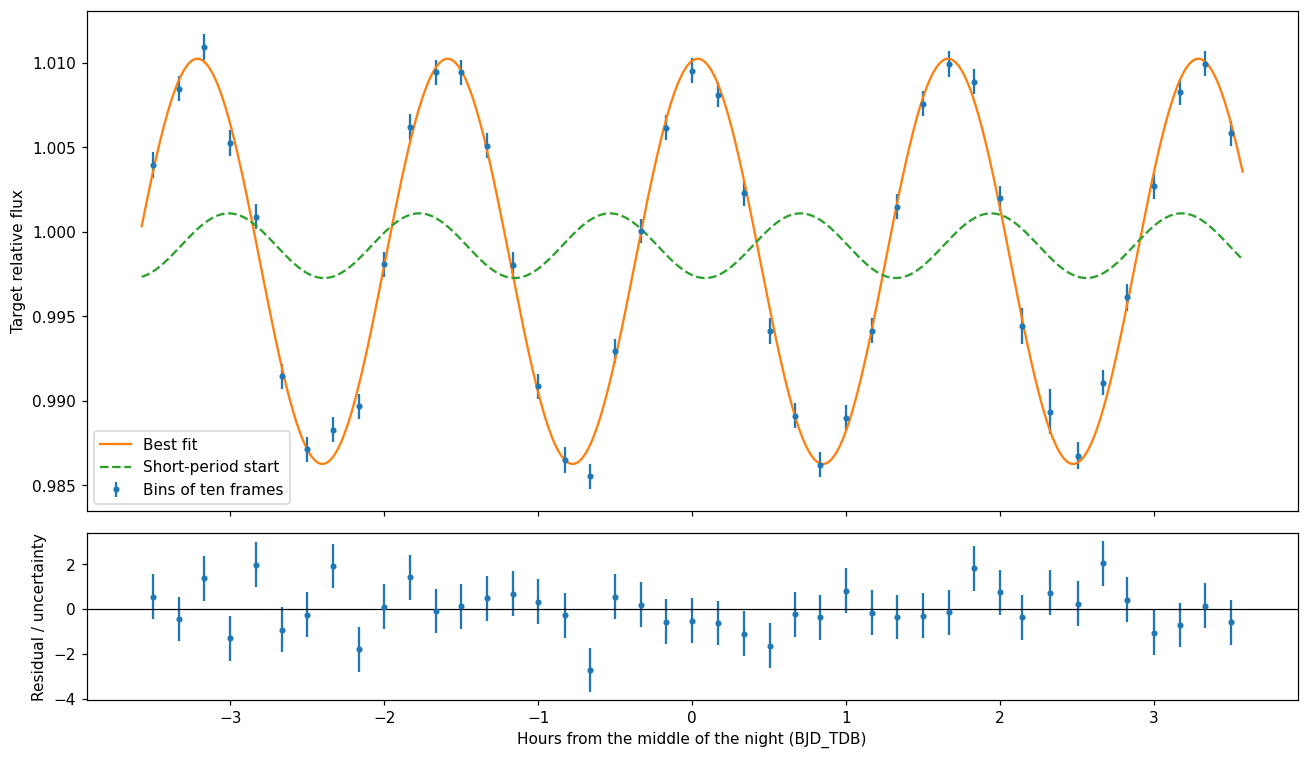

In [11]:
def sinusoid(t, f0, A, P, phi):
    """Relative flux of a star varying sinusoidally about the mean f0,
    with fractional semi-amplitude A, period P (in the units of t) and
    phase phi (in radians) at t = 0."""
    return f0 * (1 + A * np.sin(2 * np.pi * t / P + phi))

# Measure time in hours from the middle of the night.
midnight_bjd = (time_bjd[0] + time_bjd[-1]) / 2
fit_time = (time_bjd - midnight_bjd) * 24
first_maximum = maximum_times[0] - (time_hours[0] + time_hours[-1]) / 2
phase_guess = (np.pi / 2 - 2 * np.pi * first_maximum / period_guess + np.pi) % (2 * np.pi) - np.pi
guess = [mean_guess, amplitude_guess, period_guess, phase_guess]

# Fit the sinusoid with the measured uncertainties.
def fit_sinusoid(t, values, errors, initial):
    parameters, covariance = curve_fit(sinusoid, t, values, p0=initial,
                                       sigma=errors, absolute_sigma=True, maxfev=20000)
    uncertainty = np.sqrt(np.diag(covariance))
    # A negative amplitude is the same curve with the phase shifted by pi.
    if parameters[1] < 0:
        parameters[1] *= -1
        parameters[3] += np.pi
    parameters[3] = (parameters[3] + np.pi) % (2 * np.pi) - np.pi
    residuals = (values - sinusoid(t, *parameters)) / errors
    reduced_chi2 = np.sum(residuals**2) / (len(values) - len(parameters))
    return parameters, uncertainty, reduced_chi2

best_parameters, best_uncertainty, best_chi2 = fit_sinusoid(
    fit_time[keep_frames], relative_flux[keep_frames], relative_flux_err[keep_frames], guess)
display(pd.DataFrame({'parameter': ['f0', 'A (fraction)', 'P (hours)', 'phi (radians)'],
                      'value': best_parameters, 'uncertainty': best_uncertainty}))
print(f'Reduced chi-square: {best_chi2:.4f}')

# Start again with a period 25% shorter.
short_guess = guess.copy()
short_guess[2] *= 0.75
short_parameters, short_uncertainty, short_chi2 = fit_sinusoid(
    fit_time[keep_frames], relative_flux[keep_frames], relative_flux_err[keep_frames], short_guess)
display(pd.DataFrame({'start': ['Estimate', '25% shorter'],
                      'P_hours': [best_parameters[2], short_parameters[2]],
                      'P_error': [best_uncertainty[2], short_uncertainty[2]],
                      'A': [best_parameters[1], short_parameters[1]],
                      'reduced_chi2': [best_chi2, short_chi2]}))

# Try using the full BJD converted to hours instead of centering the times.
try:
    with warnings.catch_warnings(record=True) as fit_warnings:
        warnings.simplefilter('always', OptimizeWarning)
        bjd_parameters, bjd_uncertainty, bjd_chi2 = fit_sinusoid(
            time_bjd[keep_frames] * 24, relative_flux[keep_frames],
            relative_flux_err[keep_frames], guess)
    display(pd.DataFrame({'parameter': ['f0', 'A (fraction)', 'P (hours)', 'phi (radians)'],
                          'full_BJD_value': bjd_parameters, 'uncertainty': bjd_uncertainty}))
    print(f'Full-BJD reduced chi-square: {bjd_chi2:.4f}')
    for warning in fit_warnings:
        print(str(warning.message))
except RuntimeError as error:
    print('Full-BJD fit did not converge:', error)

# Bin the data in groups of ten original frames, omitting rejected points.
bin_time, bin_flux, bin_error, bin_residual = [], [], [], []
for start in range(0, n_frames, 10):
    indices = np.arange(start, min(start + 10, n_frames))
    indices = indices[keep_frames[indices]]
    if len(indices) == 0:
        continue
    weights = 1 / relative_flux_err[indices]**2
    bin_time.append(np.average(fit_time[indices], weights=weights))
    bin_flux.append(np.average(relative_flux[indices], weights=weights))
    bin_error.append(np.sum(weights)**-0.5)
    model = sinusoid(fit_time[indices], *best_parameters)
    bin_residual.append(np.average(relative_flux[indices] - model, weights=weights) / bin_error[-1])

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1]})
smooth_time = np.linspace(fit_time.min(), fit_time.max(), 2000)
axes[0].errorbar(bin_time, bin_flux, yerr=bin_error, fmt='.', label='Bins of ten frames')
axes[0].plot(smooth_time, sinusoid(smooth_time, *best_parameters), label='Best fit')
axes[0].plot(smooth_time, sinusoid(smooth_time, *short_parameters), '--', label='Short-period start')
axes[0].set_ylabel('Target relative flux')
axes[0].legend()
axes[1].errorbar(bin_time, bin_residual, yerr=np.ones(len(bin_time)), fmt='.')
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_ylabel('Residual / uncertainty')
axes[1].set_xlabel('Hours from the middle of the night (BJD_TDB)')
fig.tight_layout()
plt.show()


##### Written

The fit gives $f_0=0.998256\pm0.000117$, $A=0.012013\pm0.000164$, $P=1.62529\pm0.00288$ hours, and $\phi=1.42866\pm0.01375$ radians, with the phase measured at the middle of the night. The reduced chi-square is about 0.945, so the remaining scatter is about what the error bars predict. The binned data follow the model pretty well, and the residuals don't show an obvious leftover repeating pattern.

Starting with a period 25% shorter gets stuck at a different fit: $P\approx1.238$ hours and $A\approx0.00192$, with a reduced chi-square of about 13.46. It has found a local minimum, but it misses most of the actual up-and-down variation. Even without knowing the correct answer, the large chi-square, poor overlap with the peaks, and repeating structure left in the residuals would tell us something went wrong. Trying several starting periods would help catch this.

Using the full BJD converted to hours also behaves badly here: the reduced chi-square is about 10.12 and the fit cannot estimate the parameter covariance, so the reported uncertainties are infinite. The huge time offset makes period and phase very tangled numerically: a tiny change in period can move the phase at those timestamps by a lot. Subtracting the middle-of-night time makes the numbers much smaller and the fit better behaved, without changing the physical model.

#### Part 3.3

In [12]:
# Repeat the fit with each choice changed one at a time.
original_relative_flux, original_relative_error = summed_relative_flux(trusted_indices, flux_err)
all_comparison_flux, all_comparison_error = summed_relative_flux(np.arange(8), updated_errors)
fit_choices = [
    ('Baseline', relative_flux, relative_flux_err, keep_frames),
    ('Outliers left in', relative_flux, relative_flux_err, all_frames),
    ('No scintillation', original_relative_flux, original_relative_error, keep_frames),
    ('C1 included', all_comparison_flux, all_comparison_error, keep_frames),
    ('Cloud removed', relative_flux, relative_flux_err, keep_frames & ~cloud_frames),
]
comparison_fits = []
for name, values, errors, mask in fit_choices:
    parameters, uncertainty, chi2 = fit_sinusoid(
        fit_time[mask], values[mask], errors[mask], best_parameters)
    comparison_fits.append({'fit': name, 'N': mask.sum(),
                            'A': parameters[1], 'A_error': uncertainty[1],
                            'P_hours': parameters[2], 'P_error_hours': uncertainty[2],
                            'reduced_chi2': chi2})
fit_comparison = pd.DataFrame(comparison_fits)
with pd.option_context('display.precision', 7, 'display.max_columns', None):
    display(fit_comparison)


,fit,N,A,A_error,P_hours,P_error_hours,reduced_chi2
0,Baseline,426,0.0120129,0.0001641,1.6252881,0.0028781,0.9448990
1,Outliers left in,430,0.0120968,0.0001634,1.6246566,0.0028373,1.3551448
2,No scintillation,426,0.0120242,0.0001093,1.6251263,0.0019235,2.1013854
3,C1 included,426,0.0100924,0.0001473,1.6300116,0.0031039,6.1297708
4,Cloud removed,390,0.0120426,0.0001708,1.6250281,0.0029923,0.9374047


##### Written

Putting the outliers back in barely moves the fitted period or amplitude compared with their uncertainties, but the reduced chi-square increases from about 0.945 to 1.355. So these few points mainly make the scatter look worse; they don't dominate the fitted curve in this dataset.

Leaving out scintillation also barely changes the best-fit values, but it makes the claimed uncertainties much smaller. The period error falls from about 0.00288 to 0.00192 hours, and the amplitude error from about 0.000164 to 0.000109. The reduced chi-square rises to about 2.10, which says the original error bars are too small for the target too. Roughly speaking, a factor of $\sqrt{2.10}\approx1.45$ in the error bars would bring that fit's reduced chi-square to one. The target is bright enough that ignoring this extra fractional noise matters quite a bit.

Putting C1 back in changes the light curve itself. The amplitude falls from about 0.01201 to 0.01009, a change much larger than the quoted amplitude errors, and the reduced chi-square jumps to about 6.13. The period also moves a little, to about 1.6300 hours, though that shift is only comparable to the combined period uncertainties. C1's own variation is leaking into the target ratio, so this isn't something we can fix just by claiming a bigger error bar.

Removing the cloudy frames changes neither parameter by much: $P\approx1.62503$ hours and $A\approx0.01204$. The uncertainties increase slightly because we have fewer measurements, and the reduced chi-square stays near one. For these data, the comparison-star choice clearly affects the inferred amplitude, while the scintillation choice mostly affects how confidently we claim to know the answer. The cloud and isolated outlier choices have only small effects on the fitted values.

#### Part 3.4

In [13]:
# Fit the first and second halves of the night separately.
half_results = []
for name, half in [('First half', fit_time < 0), ('Second half', fit_time >= 0)]:
    mask = keep_frames & half
    parameters, uncertainty, chi2 = fit_sinusoid(
        fit_time[mask], relative_flux[mask], relative_flux_err[mask], best_parameters)
    half_results.append({'fit': name, 'N': mask.sum(),
                         'A': parameters[1], 'A_error': uncertainty[1],
                         'P_hours': parameters[2], 'P_error_hours': uncertainty[2],
                         'reduced_chi2': chi2,
                         'P_error_ratio': uncertainty[2] / best_uncertainty[2]})
half_fits = pd.DataFrame(half_results)
with pd.option_context('display.precision', 7, 'display.max_columns', None):
    display(half_fits)
print(f'Whole night: P = {best_parameters[2]:.6f} +/- {best_uncertainty[2]:.6f} hours')
periods = half_fits['P_hours'].to_numpy()
period_errors = half_fits['P_error_hours'].to_numpy()
print('Difference between halves / combined uncertainty:',
      abs(periods[0] - periods[1]) / np.hypot(*period_errors))
# The full-night fit shares data with both halves, so these comparisons are correlated.
print('Difference from whole night / quadrature uncertainty:',
      np.abs(periods - best_parameters[2]) / np.hypot(period_errors, best_uncertainty[2]))
print(f'Count-only uncertainty factor: sqrt(2) = {np.sqrt(2):.3f}')
print(f'Count and time-baseline estimate: 2 * sqrt(2) = {2 * np.sqrt(2):.3f}')


Whole night: P = 1.625288 +/- 0.002878 hours
Difference between halves / combined uncertainty: 0.2740638196986188
Difference from whole night / quadrature uncertainty: [0.64898491 0.91515199]
Count-only uncertainty factor: sqrt(2) = 1.414
Count and time-baseline estimate: 2 * sqrt(2) = 2.828


,fit,N,A,A_error,P_hours,P_error_hours,reduced_chi2,P_error_ratio
0,First half,213,0.0122605,0.0002296,1.6306294,0.0077108,1.1071670,2.6791913
1,Second half,213,0.0117667,0.0002355,1.6338594,0.0089129,0.7802963,3.0968762


##### Written

The first half gives $P=1.63063\pm0.00771$ hours, and the second half gives $P=1.63386\pm0.00891$ hours. They agree with each other: their difference is only about 0.27 times their combined uncertainty. Both are also within one quoted uncertainty of the whole-night value, $1.62529\pm0.00288$ hours. The whole-night fit shares data with the halves, so those comparisons are correlated, but there isn't an obvious disagreement suggesting that the period error is wildly optimistic.

The period uncertainties from the two halves are about 2.68 and 3.10 times the whole-night uncertainty, considerably larger than $\sqrt{2}$. Halving the night loses both measurements and time leverage. Over a long stretch, even a slightly wrong period builds up a noticeable shift between the predicted and observed peaks; over a shorter stretch, that same wrong period can still line up reasonably well. Very roughly, period uncertainty scales like $1/(T\sqrt{N})$ if the amplitude and point uncertainties stay similar, so halving both the time span and the number of points gives a factor of $2\sqrt{2}\approx2.83$. That is pretty close to what we get.

### AI Use Statement

I used AI in this problem set for the following tasks:

1. Help with importing frames from files.
2. Formatting of markdown text (bolding, writing e- properly, converting my shorthand formulas to their formal equivalents, and fixing my latex). AI was not used to actually write any discussion text or to make any claims.
3. Help with plotting libraries.
4. Writing coherent and efficient print statements
5. Determining if particular functions existed in numpy or astropy or matplotlib libraries, and quickly referencing the documentation of these functions.
